# Wizualizacja danych

Wykres często mówi więcej niż tabela liczb. Na tym etapie kursu **nie tworzymy wykresów od zera** – przeglądamy gotowe przykłady i sprawdzamy, jakie możliwości mają najpopularniejsze biblioteki. Do własnych projektów wystarczy skopiować i zmodyfikować odpowiedni przykład.

**Plan notatnika:**
1. Wykresy w Pandas (`.plot()`) – szybka eksploracja danych
2. Matplotlib – podstawy (interfejs `pyplot`)
3. Matplotlib – interfejs obiektowy (`fig`, `ax`)
4. Style i zapis wykresów do pliku
5. Seaborn – wykresy statystyczne
6. Plotly – wykresy interaktywne

**Przydatne linki:** [Matplotlib](https://matplotlib.org/), [Seaborn](https://seaborn.pydata.org/), [Plotly](https://plotly.com/python/).

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Wykresy w Pandas

Do szybkiej, wstępnej analizy wizualnej często wystarcza sama biblioteka Pandas: każda seria i tabela ma metodę `.plot()`, która w środku korzysta z Matplotlib.

### Dane z internetu

Wczytamy dwa zbiory: **drinks** (spożycie alkoholu w 193 krajach) oraz **imdb_1000** (1000 najlepiej ocenianych filmów).

Tak jak w notatniku o Pandas przygotowaliśmy **dwie wersje** funkcji `wczytaj_csv_z_internetu(url)`. **Uruchom komórkę dla swojego systemu** (wersja dla macOS działa także na Windowsie):

| System | Sposób | Uwagi |
|---|---|---|
| **Windows** | bezpośrednio `pd.read_csv(url)` | Windows ma własny magazyn certyfikatów, więc zwykle działa od razu |
| **macOS** (i Linux) | pobranie tekstu przez `requests`, potem `pd.read_csv` | na macOS `pd.read_csv('https://...')` często kończy się błędem `CERTIFICATE_VERIFY_FAILED` |

In [7]:
import requests
from io import StringIO

URL = 'https://raw.githubusercontent.com/justmarkham/pandas-videos/master/data/'

**Wersja dla Windows** (uruchom tylko na Windowsie):

In [8]:
def wczytaj_csv_z_internetu(url, **kwargs):
    return pd.read_csv(url, **kwargs)

**Wersja dla macOS i Linux** (uruchom na macOS; działa także na Windowsie):

In [9]:
def wczytaj_csv_z_internetu(url, **kwargs):
    odpowiedz = requests.get(url, timeout=30)
    odpowiedz.raise_for_status()
    return pd.read_csv(StringIO(odpowiedz.text), **kwargs)

In [10]:
drinks = wczytaj_csv_z_internetu(URL + 'drinks.csv')
movies = wczytaj_csv_z_internetu(URL + 'imdb_1000.csv')
movies[['title', 'genre', 'duration']].head()

,title,genre,duration
0,The Shawshank Redemption,Crime,142
1,The Godfather,Crime,175
2,The Godfather: Part II,Crime,200
3,The Dark Knight,Action,152
4,Pulp Fiction,Crime,154


### Histogram

Histogram pokazuje, ile obserwacji wpada w kolejne przedziały wartości (parametr `bins` to liczba przedziałów).

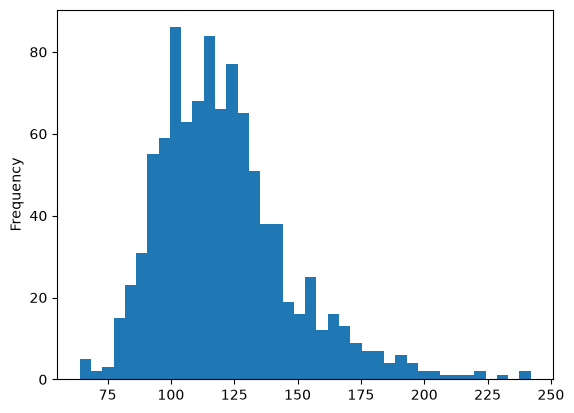

In [11]:
movies['duration'].plot(kind='hist', bins=40);

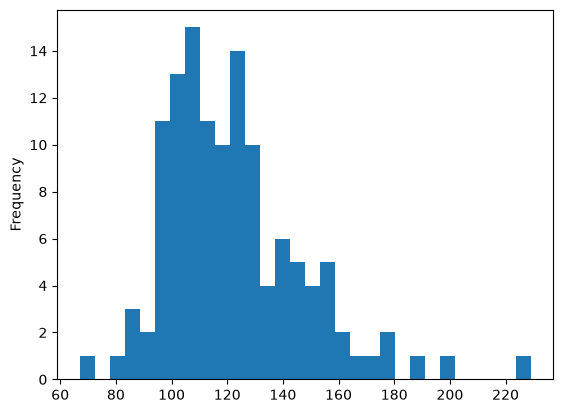

In [12]:
movies[movies['genre'] == 'Crime']['duration'].plot(kind='hist', bins=30);

### Rodzaje wykresów w `DataFrame.plot(kind='...')`

- `'bar'`, `'barh'` – wykresy słupkowe (pionowe i poziome)
- `'hist'` – histogram
- `'box'` – wykres pudełkowy
- `'kde'`, `'density'` – wykres gęstości
- `'area'` – wykres warstwowy
- `'scatter'` – wykres rozrzutu
- `'hexbin'` – wykres rozrzutu z sześciokątnymi przedziałami
- `'pie'` – wykres kołowy

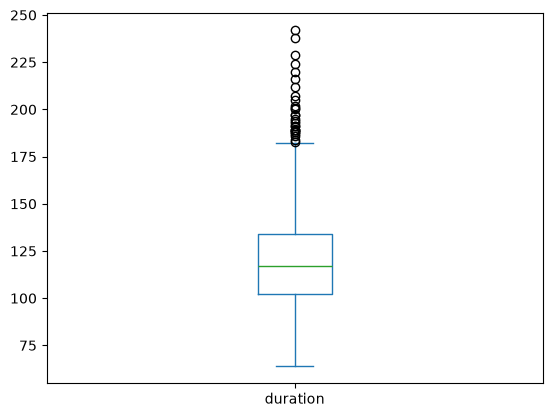

In [13]:
# wykres pudełkowy (box plot): mediana, kwartyle i wartości odstające
movies['duration'].plot(kind='box');

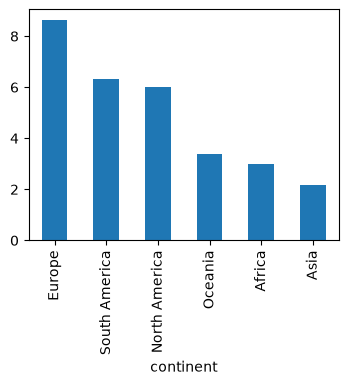

In [14]:
# średnie spożycie alkoholu według kontynentów
drinks.groupby('continent')['total_litres_of_pure_alcohol'].mean().sort_values(ascending=False).plot(kind='bar', figsize=(4, 3));

## 2. Matplotlib – podstawy (interfejs `pyplot`)

Matplotlib jest podstawową biblioteką do wizualizacji danych w Pythonie i fundamentem dla Pandas oraz Seaborn.

- **Wszechstronność** – wykresy liniowe, słupkowe, punktowe, kołowe, histogramy, wykresy pudełkowe i wiele innych.
- **Pełna kontrola** – tytuł, osie, legenda, kolory i rozmiar każdego elementu można dostosować.
- **Wiele formatów zapisu** – PNG, JPG, PDF, SVG i inne.
- **Wieloplatformowość** – działa tak samo na Windows, macOS i Linuksie.

Dokumentacja: [matplotlib.org](https://matplotlib.org/stable/contents.html).

In [15]:
import matplotlib
matplotlib.__version__

'3.11.1'

Matplotlib oferuje dwa interfejsy do tworzenia wykresów:
1. **`pyplot`** – prosty interfejs w stylu MATLAB-a: kolejne polecenia `plt.plot()`, `plt.title()` działają na „bieżącym” wykresie. Szybki w użyciu.
2. **Obiektowy** – jawnie tworzymy figurę (`fig`) i osie (`ax`) i wywołujemy ich metody. Daje większą kontrolę (sekcja 3).

### Wykres liniowy

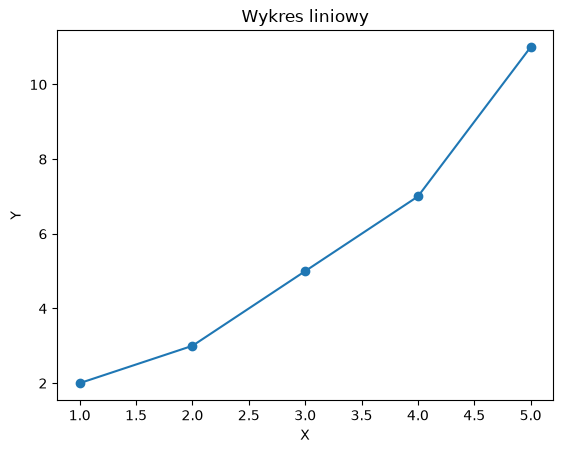

In [16]:
x = [1, 2, 3, 4, 5]
y = [2, 3, 5, 7, 11]

plt.plot(x, y, marker='o')
plt.title("Wykres liniowy")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

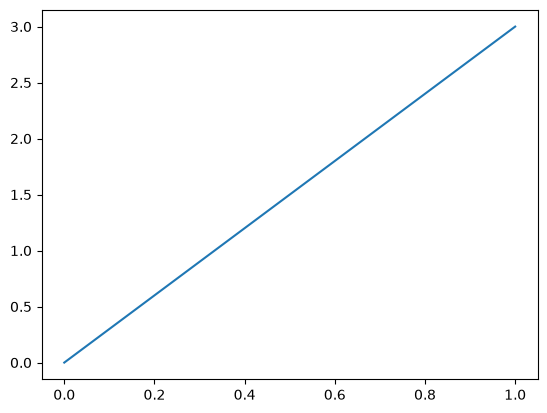

In [17]:
plt.plot([0, 1], [0, 3]);

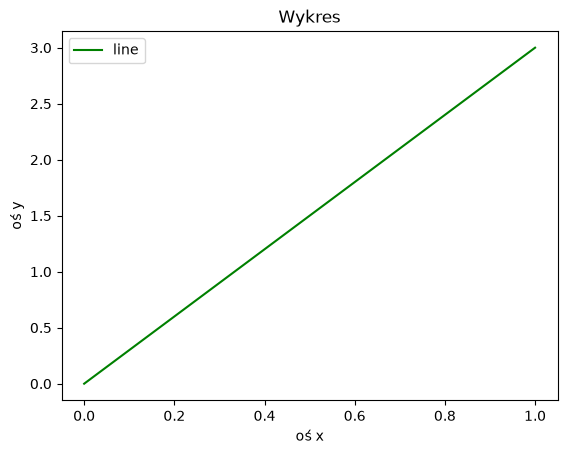

In [18]:
plt.plot([0, 1], [0, 3], label='line', color='green')
plt.xlabel('oś x')
plt.ylabel('oś y')
plt.title('Wykres')
plt.legend();

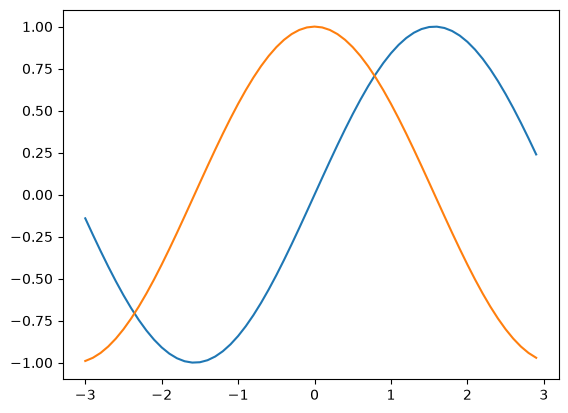

In [19]:
x = np.arange(-3, 3, 0.1)
x_sin = np.sin(x)
x_cos = np.cos(x)

plt.plot(x, x_sin)
plt.plot(x, x_cos);

### Kilka wykresów obok siebie

`plt.subplot(121)` oznacza: siatka 1 wiersz x 2 kolumny, wykres numer 1.

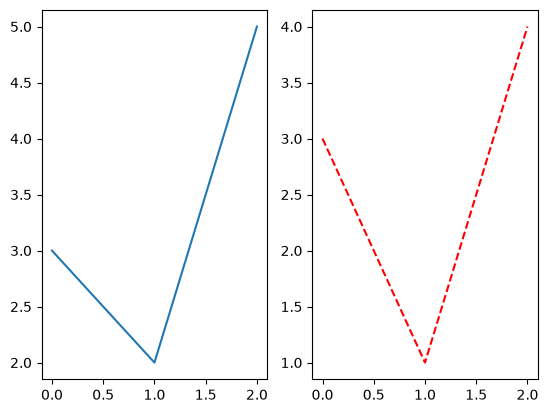

In [20]:
plt.subplot(121)
plt.plot([0, 1, 2], [3, 2, 5])
plt.subplot(122)
plt.plot([0, 1, 2], [3, 1, 4], 'r--');

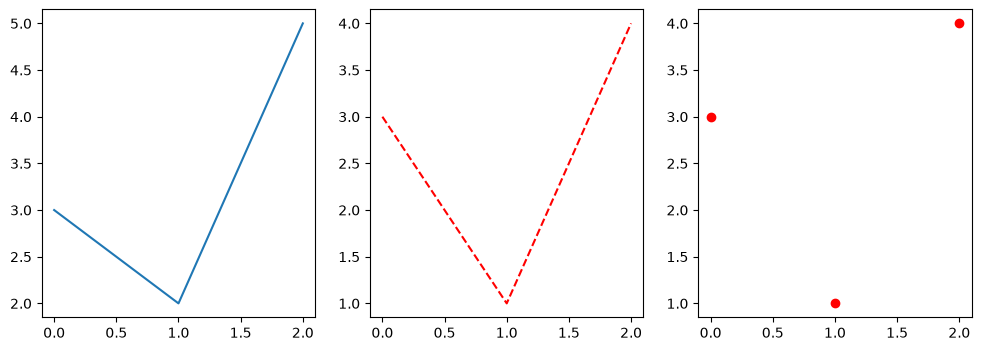

In [21]:
fig = plt.figure(figsize=(12, 4))

plt.subplot(131)
plt.plot([0, 1, 2], [3, 2, 5])
plt.subplot(132)
plt.plot([0, 1, 2], [3, 1, 4], 'r--')
plt.subplot(133)
plt.plot([0, 1, 2], [3, 1, 4], 'ro');

### Wykresy słupkowe

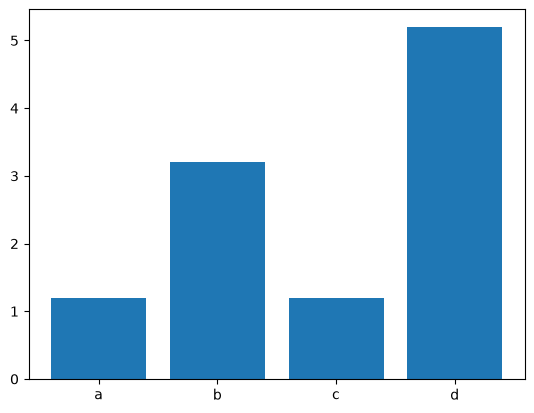

In [22]:
plt.bar(x=['a', 'b', 'c', 'd'], height=[1.2, 3.2, 1.2, 5.2]);

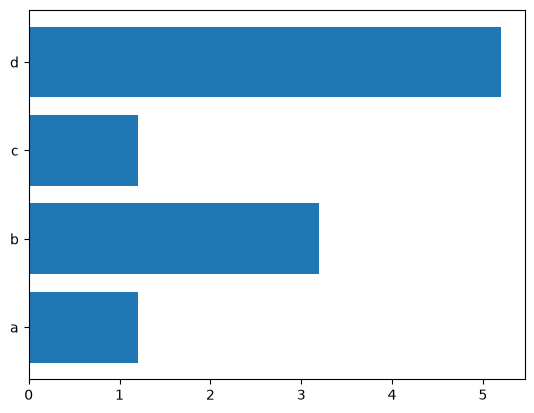

In [23]:
plt.barh(y=['a', 'b', 'c', 'd'], width=[1.2, 3.2, 1.2, 5.2]);

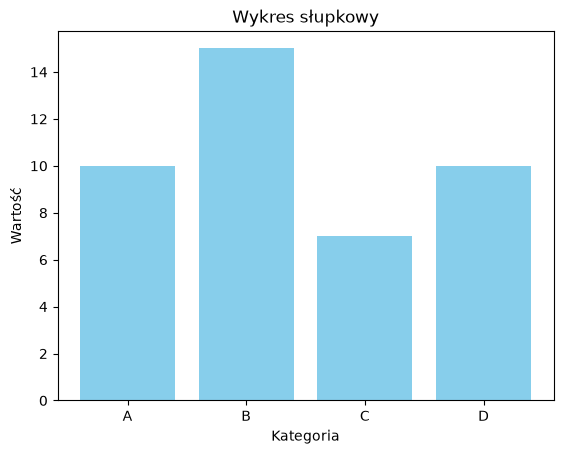

In [24]:
categories = ['A', 'B', 'C', 'D']
values = [10, 15, 7, 10]

plt.bar(categories, values, color='skyblue')
plt.title("Wykres słupkowy")
plt.xlabel("Kategoria")
plt.ylabel("Wartość")
plt.show()

### Histogram

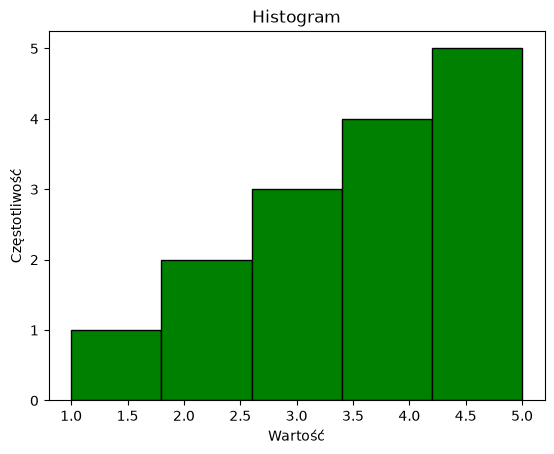

In [25]:
data = [1, 2, 2, 3, 3, 3, 4, 4, 4, 4, 5, 5, 5, 5, 5]

plt.hist(data, bins=5, color='green', edgecolor='black')
plt.title("Histogram")
plt.xlabel("Wartość")
plt.ylabel("Częstotliwość")
plt.show()

### Wykres pudełkowy (box plot)

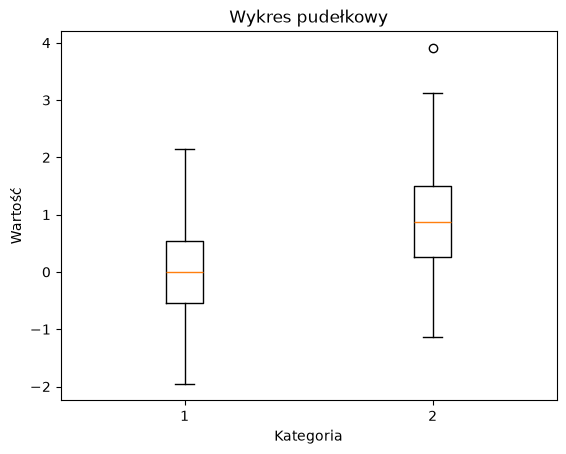

In [26]:
rng = np.random.default_rng(42)
data = [rng.normal(size=100), rng.normal(size=100) + 1]

plt.boxplot(data)
plt.title("Wykres pudełkowy")
plt.xlabel("Kategoria")
plt.ylabel("Wartość")
plt.show()

### Wykres rozrzutu (scatter plot)

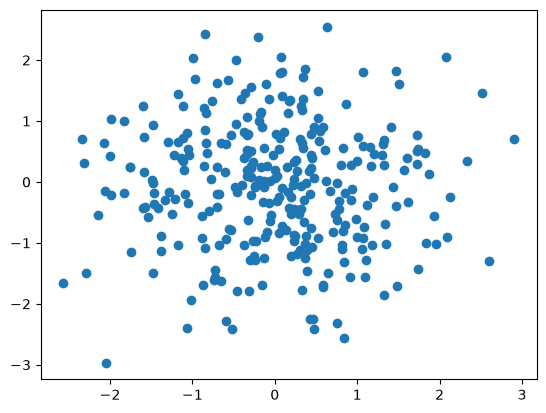

In [27]:
x1 = rng.normal(size=300)
x2 = rng.normal(size=300)

plt.scatter(x=x1, y=x2);

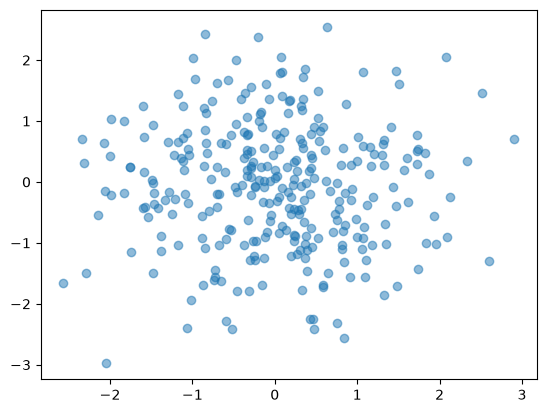

In [28]:
plt.scatter(x=x1, y=x2, alpha=0.5);   # alpha - przezroczystość punktów

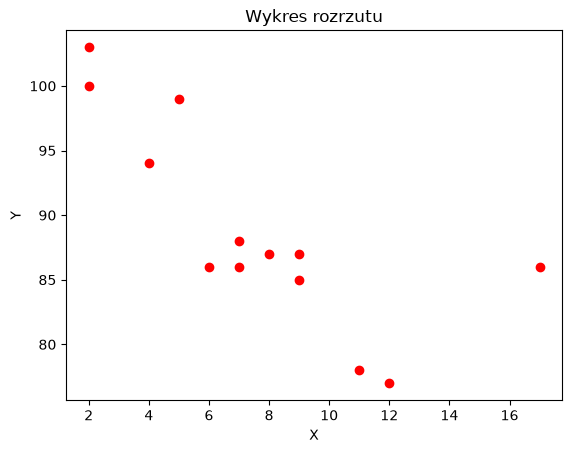

In [29]:
x = [5, 7, 8, 7, 2, 17, 2, 9, 4, 11, 12, 9, 6]
y = [99, 86, 87, 88, 100, 86, 103, 87, 94, 78, 77, 85, 86]

plt.scatter(x, y, color='red')
plt.title("Wykres rozrzutu")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

## 3. Matplotlib – interfejs obiektowy

W interfejsie obiektowym pracujemy na dwóch obiektach:
- **figura** (`fig`) – całe „okno” wykresu,
- **osie** (`ax`) – pojedynczy wykres (z osiami, tytułem, legendą) wewnątrz figury.

### `plt.figure()`

`plt.figure()` tworzy pustą figurę bez osi. Osie dodajemy ręcznie – to przydatne przy nietypowych układach.

In [30]:
fig = plt.figure()

<Figure size 640x480 with 0 Axes>

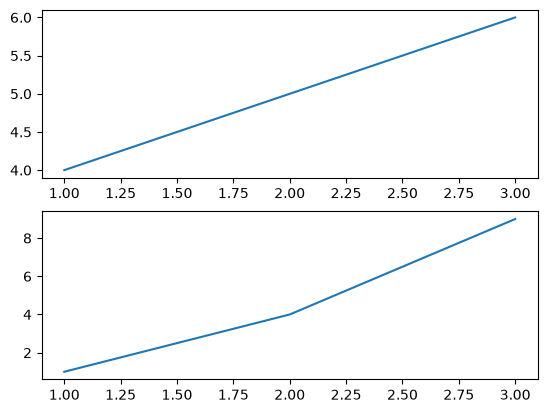

In [31]:
fig = plt.figure()

ax1 = fig.add_subplot(211)  # pierwsza oś w układzie 2x1
ax2 = fig.add_subplot(212)  # druga oś w układzie 2x1

ax1.plot([1, 2, 3], [4, 5, 6])
ax2.plot([1, 2, 3], [1, 4, 9])

plt.show()

### `plt.subplots()`

`plt.subplots()` tworzy jednocześnie figurę i zestaw osi. To najwygodniejszy sposób na standardowe układy (np. siatka wykresów).

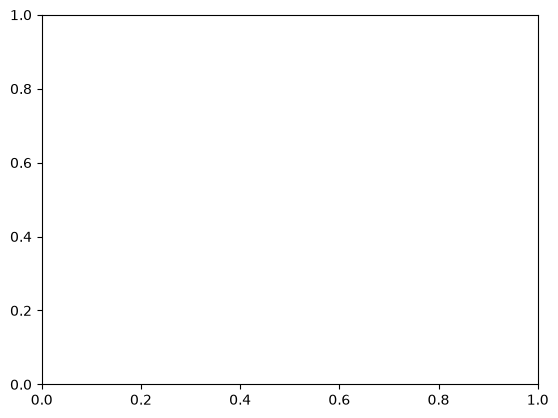

In [32]:
fig, ax = plt.subplots()

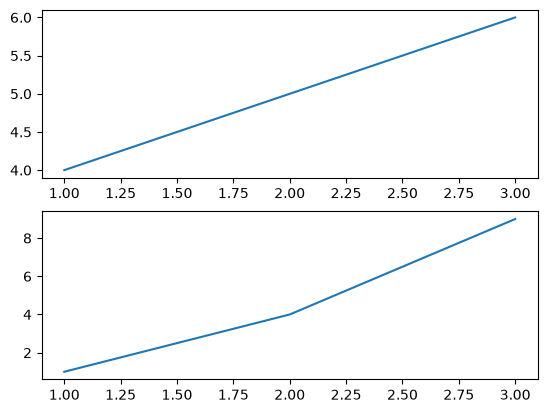

In [33]:
fig, (ax1, ax2) = plt.subplots(2, 1)   # układ 2x1

ax1.plot([1, 2, 3], [4, 5, 6])
ax2.plot([1, 2, 3], [1, 4, 9])

plt.show()

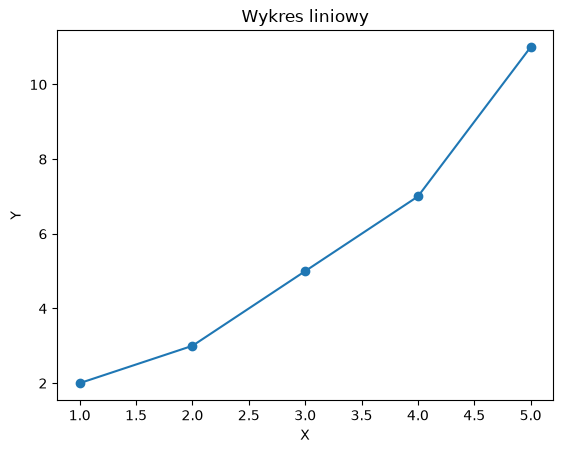

In [34]:
fig, ax = plt.subplots()

x = [1, 2, 3, 4, 5]
y = [2, 3, 5, 7, 11]

ax.plot(x, y, marker='o')
ax.set_title("Wykres liniowy")
ax.set_xlabel("X")
ax.set_ylabel("Y")

plt.show()

### Wykresy wielopanelowe

Przy siatce wykresów `axs` jest tablicą NumPy – wybieramy panel przez `axs[wiersz, kolumna]`.

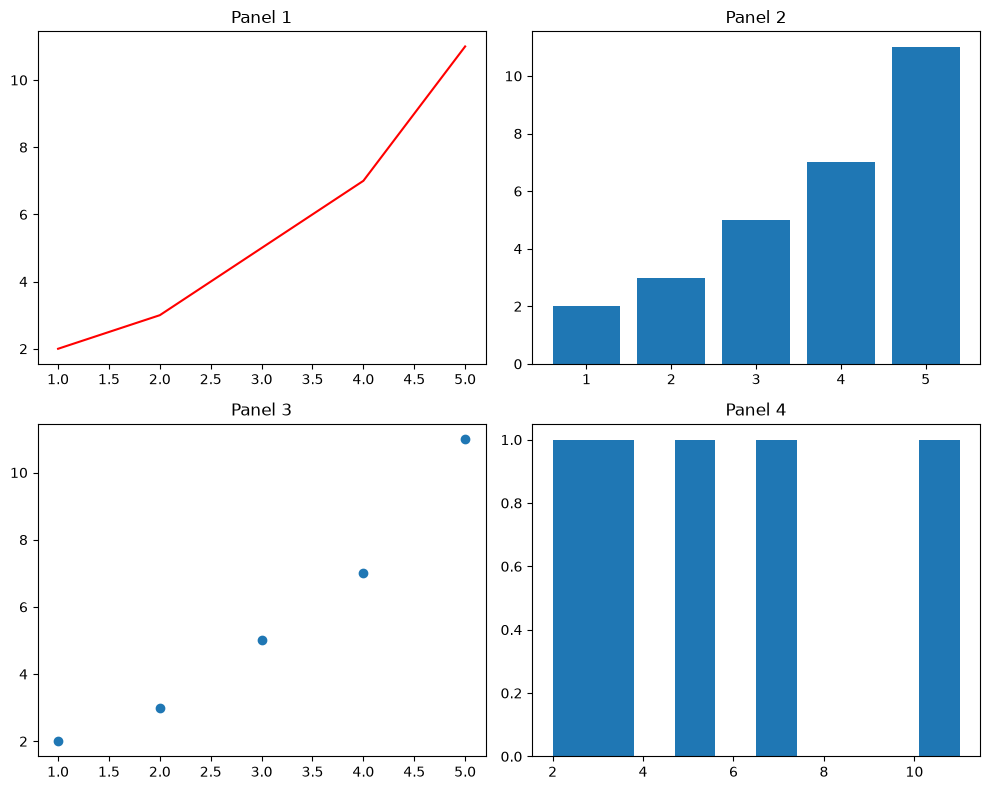

In [35]:
fig, axs = plt.subplots(2, 2, figsize=(10, 8))

x = [1, 2, 3, 4, 5]
y = [2, 3, 5, 7, 11]

axs[0, 0].plot(x, y, 'r')
axs[0, 0].set_title('Panel 1')
axs[0, 1].bar(x, y)
axs[0, 1].set_title('Panel 2')
axs[1, 0].scatter(x, y)
axs[1, 0].set_title('Panel 3')
axs[1, 1].hist(y)
axs[1, 1].set_title('Panel 4')

plt.tight_layout()   # automatyczne odstępy między panelami
plt.show()

### Adnotacje

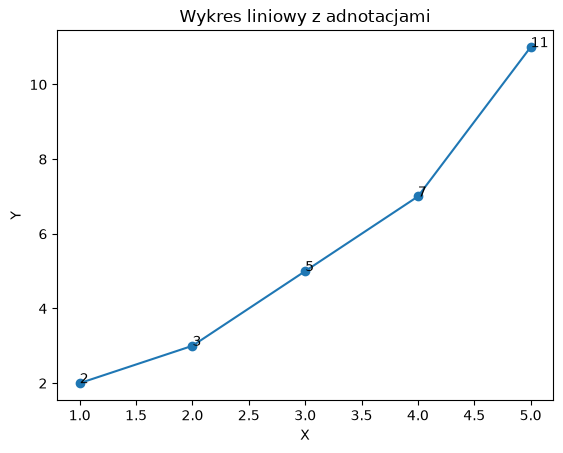

In [36]:
fig, ax = plt.subplots()

x = [1, 2, 3, 4, 5]
y = [2, 3, 5, 7, 11]

ax.plot(x, y, marker='o')

# podpis wartości przy każdym punkcie
for i, txt in enumerate(y):
    ax.annotate(txt, (x[i], y[i]))

ax.set_title("Wykres liniowy z adnotacjami")
ax.set_xlabel("X")
ax.set_ylabel("Y")

plt.show()

### Wiele serii danych na jednym wykresie

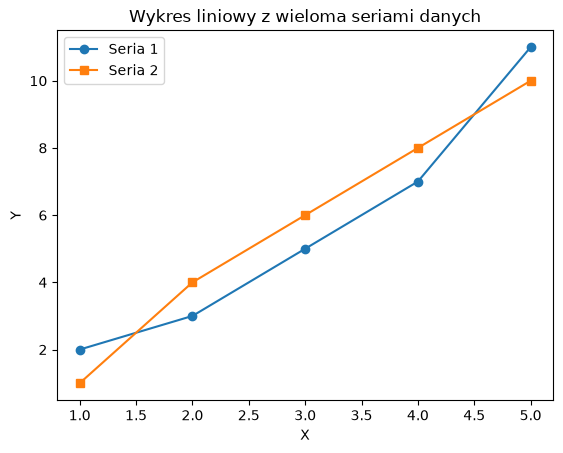

In [37]:
x = [1, 2, 3, 4, 5]
y1 = [2, 3, 5, 7, 11]
y2 = [1, 4, 6, 8, 10]

fig, ax = plt.subplots()

ax.plot(x, y1, label='Seria 1', marker='o')
ax.plot(x, y2, label='Seria 2', marker='s')

ax.set_title("Wykres liniowy z wieloma seriami danych")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.legend()

plt.show()

### Podwójna oś Y

Gdy dwie serie mają zupełnie różne skale, rysujemy je na osobnych osiach Y (`twinx()`).

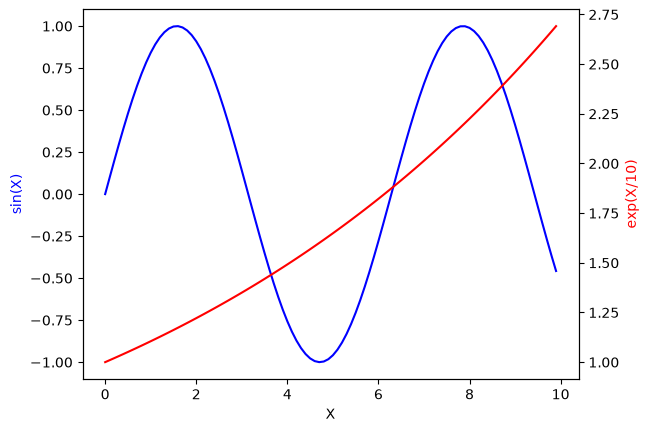

In [38]:
x = np.arange(0, 10, 0.1)
y1 = np.sin(x)
y2 = np.exp(x / 10)

fig, ax1 = plt.subplots()

ax1.plot(x, y1, 'b-')
ax1.set_xlabel("X")
ax1.set_ylabel("sin(X)", color='b')

ax2 = ax1.twinx()           # druga oś Y współdzieląca oś X
ax2.plot(x, y2, 'r-')
ax2.set_ylabel("exp(X/10)", color='r')

plt.show()

### Wykres rozrzutu 3D

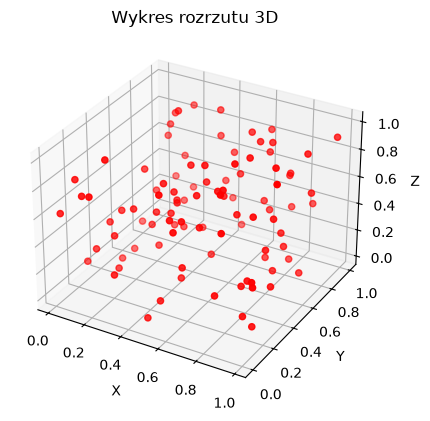

In [39]:
x = rng.random(100)
y = rng.random(100)
z = rng.random(100)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(x, y, z, c='r', marker='o')

ax.set_title("Wykres rozrzutu 3D")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.show()

## 4. Style i zapis wykresów

### Style

Cały wygląd wykresów (kolory, siatka, czcionki) zmienia jedno polecenie `plt.style.use('nazwa')`. Dostępne style:

In [40]:
plt.style.available

['Solarize_Light2',
 'bmh',
 'classic',
 'company',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'petroff6',
 'petroff8',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

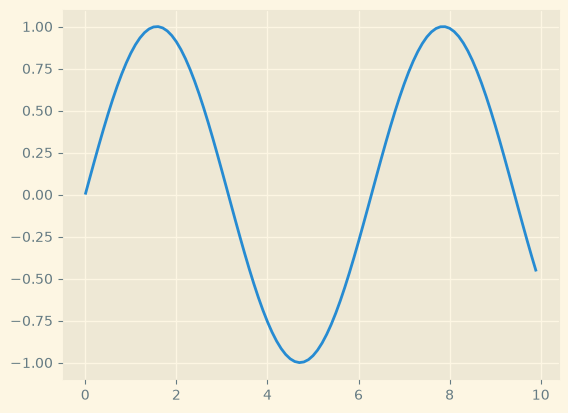

In [41]:
x = np.arange(0, 10, 0.1)
x_sin = np.sin(x)

plt.style.use('Solarize_Light2')
plt.plot(x, x_sin);

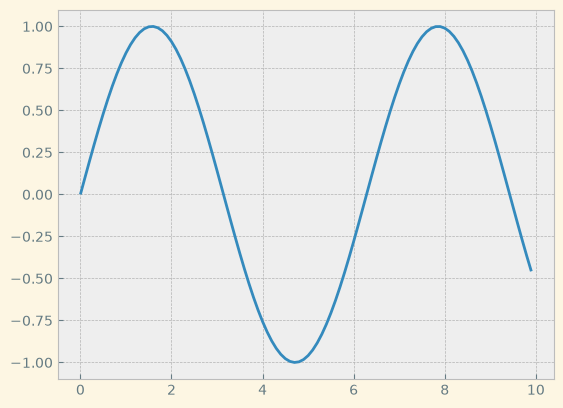

In [42]:
plt.style.use('bmh')
plt.plot(x, x_sin);

> **Uwaga.** W starszych tutorialach spotkasz styl `'seaborn'`. W obecnych wersjach Matplotlib nazywa się `'seaborn-v0_8'` (oraz `'seaborn-v0_8-whitegrid'` itd.).

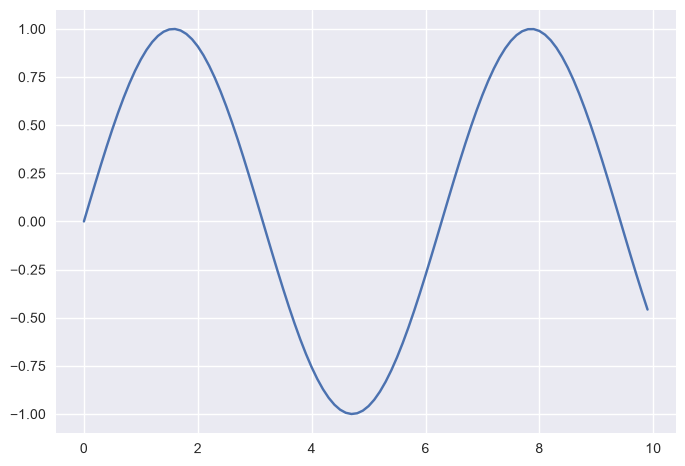

In [43]:
plt.style.use('seaborn-v0_8')
plt.plot(x, x_sin);

In [44]:
plt.style.use('default')   # powrót do domyślnego wyglądu

### Zapis wykresu do pliku (`.png`, `.jpg`, `.pdf`)

Format pliku wynika z rozszerzenia nazwy. Przydatne parametry:
- `dpi` – rozdzielczość obrazu w punktach na cal (*dots per inch*),
- `bbox_inches='tight'` – odcina nadmiarowe marginesy wokół wykresu.

Pliki zapisują się w folderze z notatnikiem.

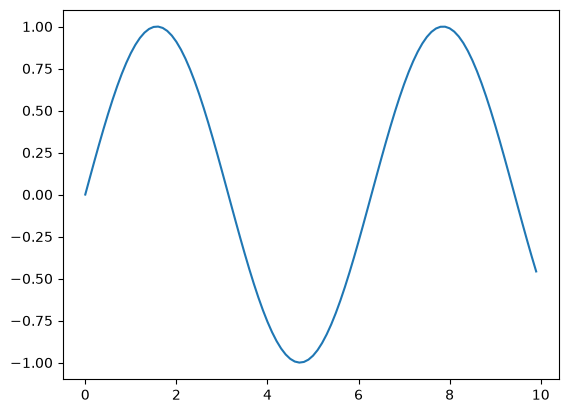

In [45]:
plt.plot(x, x_sin)
plt.savefig('sinus.png', dpi=150, bbox_inches='tight')
plt.savefig('sinus.jpg')
plt.savefig('sinus.pdf')

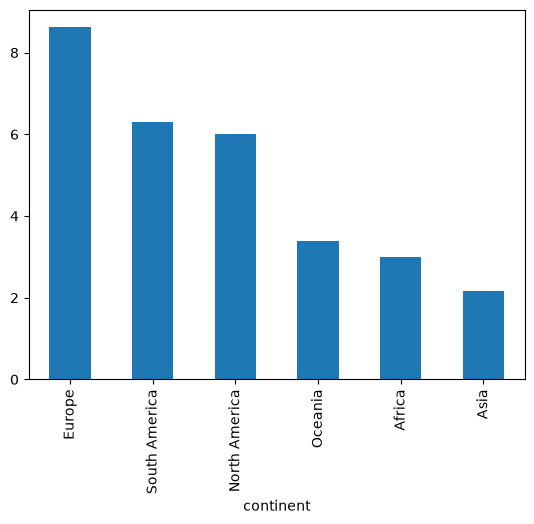

In [46]:
# wykres z Pandas: pobieramy z niego figurę i zapisujemy ją
wykres = drinks.groupby('continent')['total_litres_of_pure_alcohol'].mean().sort_values(ascending=False).plot(kind='bar').get_figure()
wykres.savefig('Wykres.jpg')

## 5. Seaborn – wykresy statystyczne

Seaborn jest zbudowany na Matplotlib i oferuje wyższy poziom abstrakcji: kilka linijek kodu wystarcza do estetycznych wykresów statystycznych. Dobrze współpracuje z tabelami Pandas: podajemy `data=` (tabela) oraz nazwy kolumn (`x=`, `y=`, `hue=` – kolor, `size=` – rozmiar punktów).

- Strona biblioteki: [seaborn.pydata.org](https://seaborn.pydata.org/)
- Dokumentacja: [seaborn.pydata.org/api.html](https://seaborn.pydata.org/api.html)

In [47]:
import seaborn as sns

sns.set_theme(font_scale=1.1)   # domyślny motyw Seaborn, nieco większa czcionka
sns.__version__

'0.13.2'

Seaborn ma wbudowane przykładowe zbiory danych. Funkcja `sns.load_dataset()` zwykle pobiera je z internetu, a u nas pliki `tips.csv` i `iris.csv` leżą w folderze notatnika (parametr `data_home='.'`), więc wszystko działa bez internetu i tak samo na każdym systemie.

Zbiór **tips**: napiwki w restauracji (rachunek, napiwek, płeć, pora dnia, dzień tygodnia, liczba osób).

In [48]:
tips = sns.load_dataset('tips', data_home='.')
tips.head(10)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
5,25.29,4.71,Male,No,Sun,Dinner,4
6,8.77,2.00,Male,No,Sun,Dinner,2
7,26.88,3.12,Male,No,Sun,Dinner,4
8,15.04,1.96,Male,No,Sun,Dinner,2
9,14.78,3.23,Male,No,Sun,Dinner,2


In [49]:
tips.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [50]:
tips.describe(include='category')

,sex,smoker,day,time
count,244,244,244,244
unique,2,2,4,2
top,Male,No,Sat,Dinner
freq,157,151,87,176


### Wykres rozrzutu (`scatterplot`)

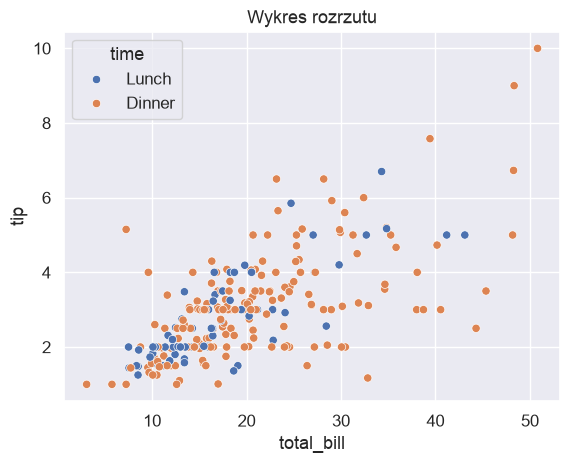

In [51]:
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time")
plt.title("Wykres rozrzutu")
plt.show()

### Histogram i wykres gęstości (`histplot`)

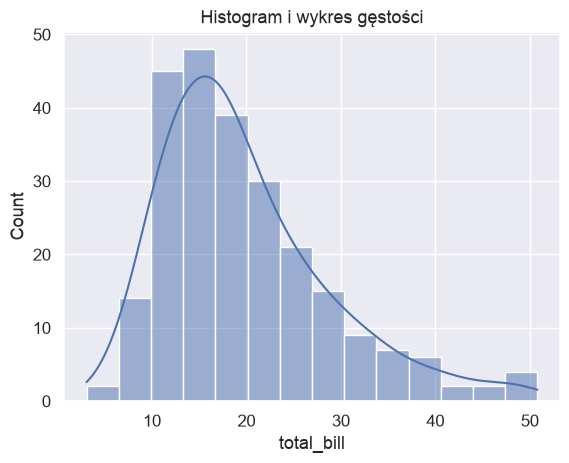

In [52]:
sns.histplot(data=tips, x="total_bill", kde=True)
plt.title("Histogram i wykres gęstości")
plt.show()

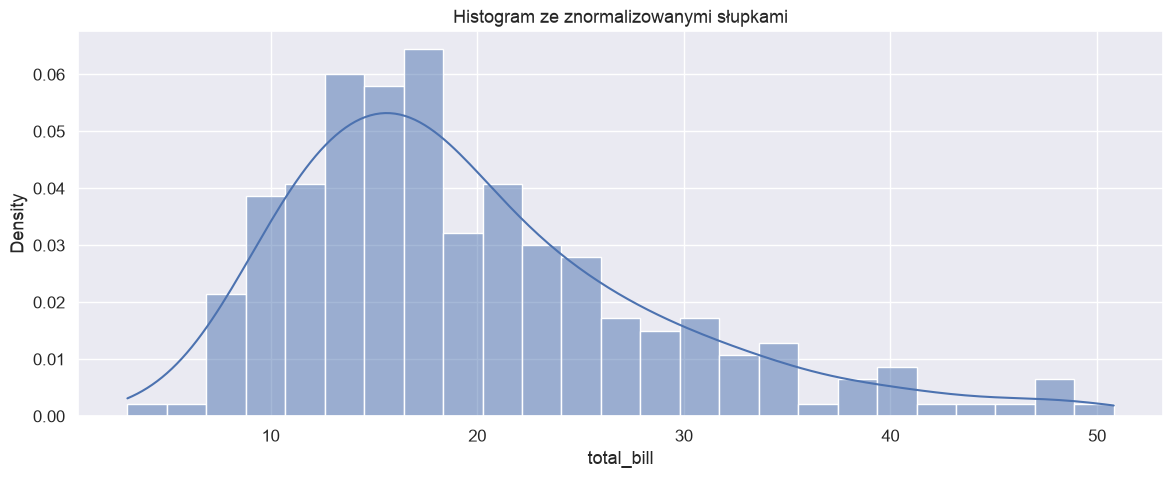

In [53]:
plt.figure(figsize=(14, 5))
sns.histplot(data=tips,
             x="total_bill",
             stat="density",    # normalizacja: pole pod histogramem równe 1
             kde=True,          # krzywa gęstości (estymator jądrowy)
             bins=25            # liczba przedziałów
            )

plt.title("Histogram ze znormalizowanymi słupkami")
plt.show()

### Wykres pudełkowy (`boxplot`)

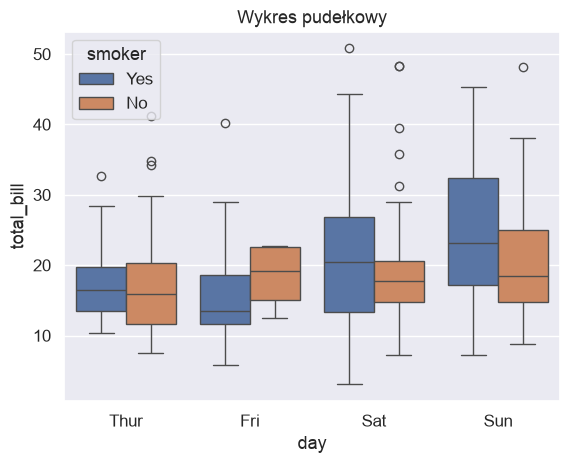

In [54]:
sns.boxplot(data=tips, x="day", y="total_bill", hue="smoker")
plt.title("Wykres pudełkowy")
plt.show()

### `relplot` – wykresy zależności

`relplot` (*relational plot*) bada relacje między dwiema lub więcej zmiennymi. Kolejne parametry dodają kolejne wymiary: rozmiar punktu (`size`), kolor (`hue`) oraz osobne panele (`col`, `row`).

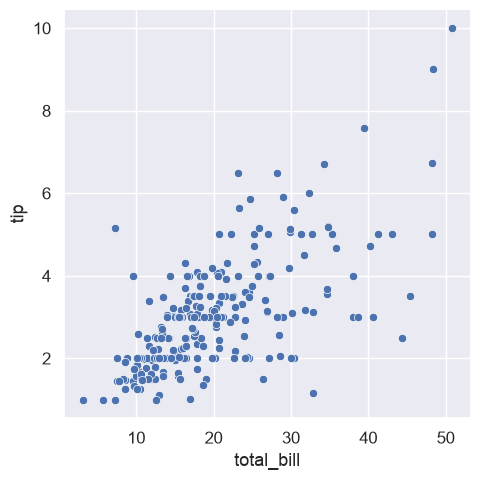

In [55]:
sns.relplot(data=tips, x='total_bill', y='tip');

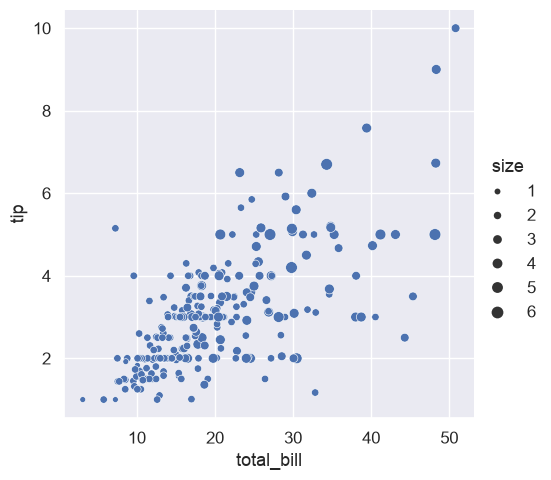

In [56]:
sns.relplot(data=tips, x='total_bill', y='tip', size='size');

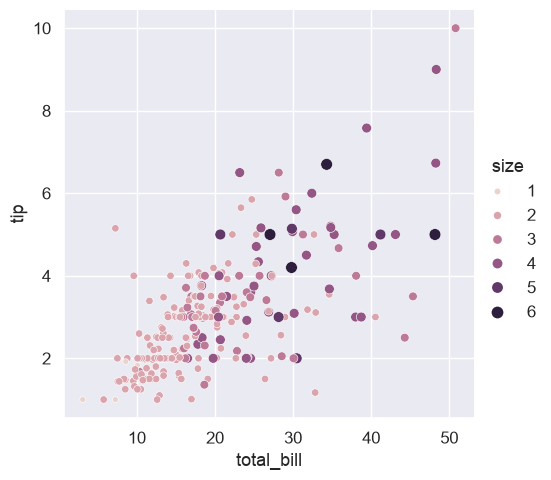

In [57]:
sns.relplot(data=tips, x='total_bill', y='tip', size='size', hue='size');

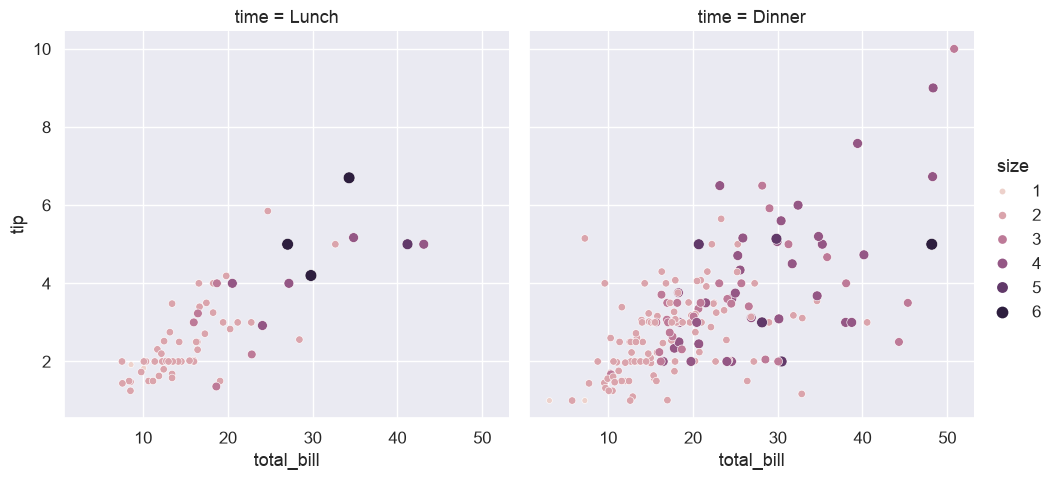

In [58]:
sns.relplot(data=tips, x='total_bill', y='tip', size='size', hue='size', col='time');

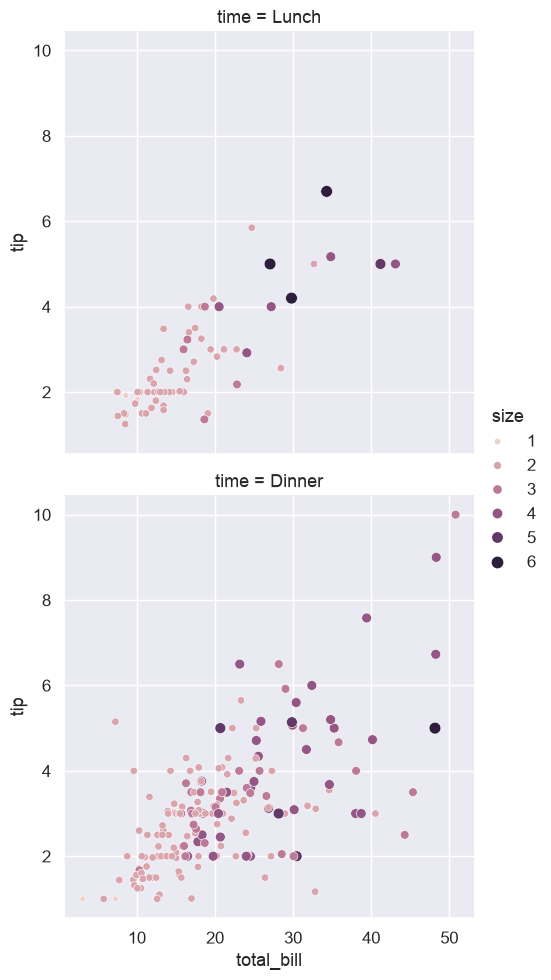

In [59]:
sns.relplot(data=tips, x='total_bill', y='tip', size='size', hue='size', row='time');

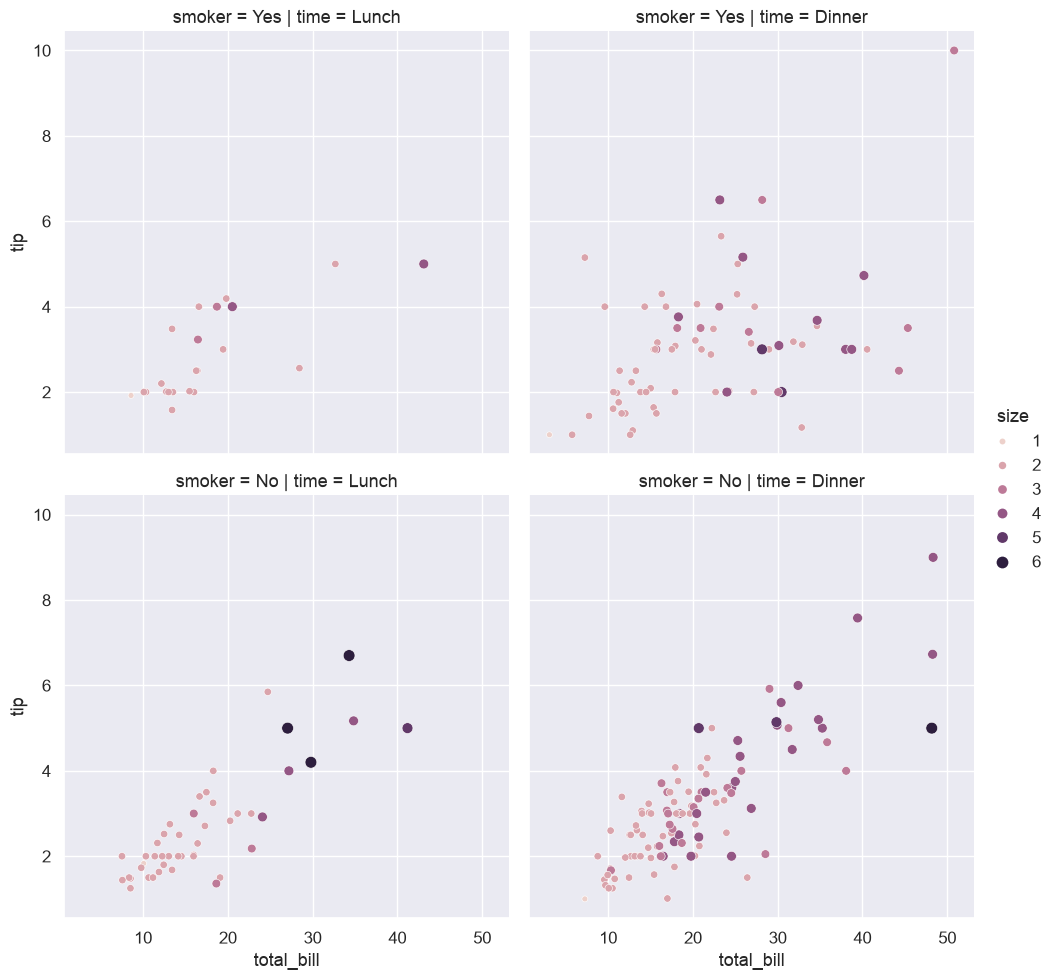

In [60]:
sns.relplot(data=tips, x='total_bill', y='tip', size='size', hue='size', col='time', row='smoker');

### `catplot` – wykresy dla zmiennych kategorycznych

`catplot` (*categorical plot*) służy do porównywania rozkładów w różnych kategoriach. Parametr `kind` wybiera rodzaj wykresu: punktowy (domyślny), `'swarm'`, `'box'` (pudełkowy), `'violin'` (skrzypcowy), `'bar'` (słupkowy) i inne.

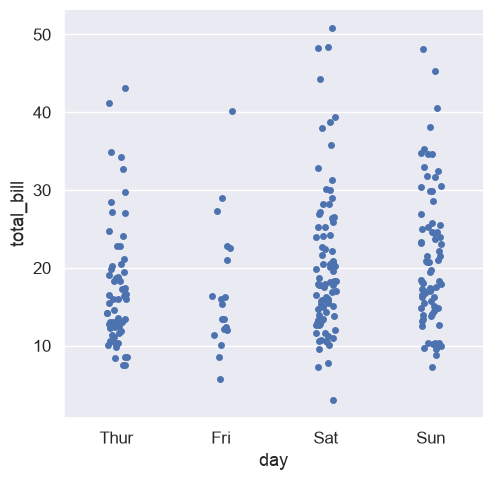

In [61]:
sns.catplot(data=tips, x='day', y='total_bill');

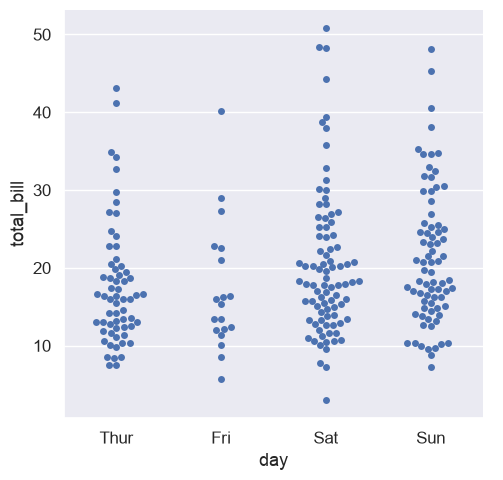

In [62]:
sns.catplot(data=tips, x='day', y='total_bill', kind='swarm');

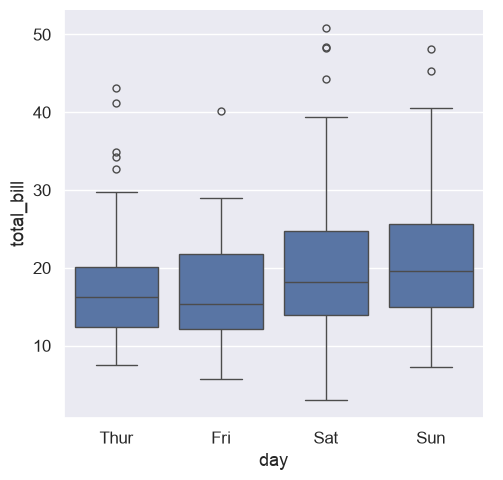

In [63]:
sns.catplot(data=tips, x='day', y='total_bill', kind='box');

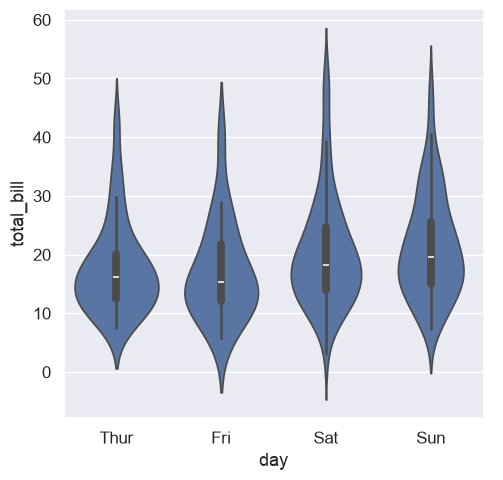

In [64]:
sns.catplot(data=tips, x='day', y='total_bill', kind='violin');

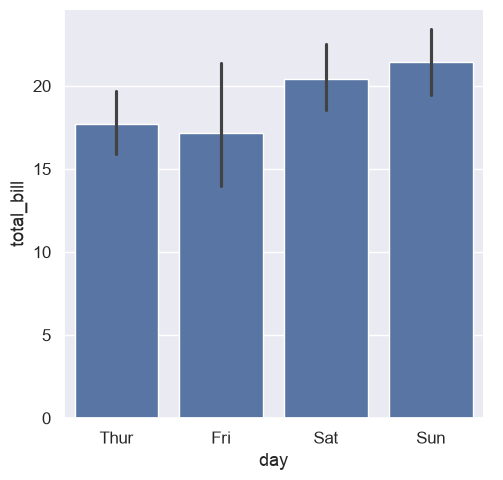

In [65]:
sns.catplot(data=tips, x='day', y='total_bill', kind='bar');

### Zbiór Iris

Klasyczny zbiór: wymiary kwiatów trzech gatunków irysów (długość i szerokość działki kielicha oraz płatka).

In [66]:
iris = sns.load_dataset('iris', data_home='.')
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


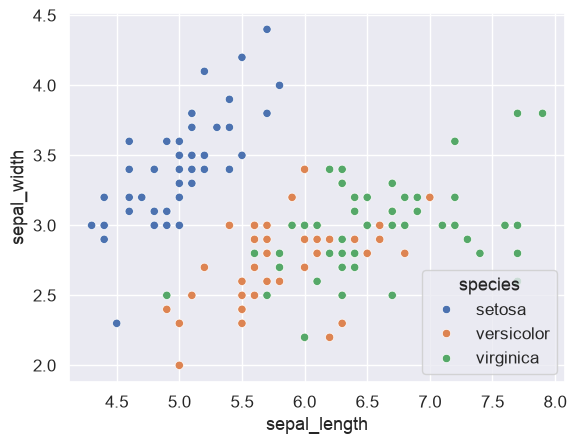

In [67]:
sns.scatterplot(x="sepal_length", y="sepal_width", data=iris, hue="species");

`pairplot` rysuje wykresy rozrzutu dla **wszystkich par** kolumn liczbowych, a na przekątnej histogramy. To jedno z najszybszych narzędzi do wstępnej eksploracji danych.

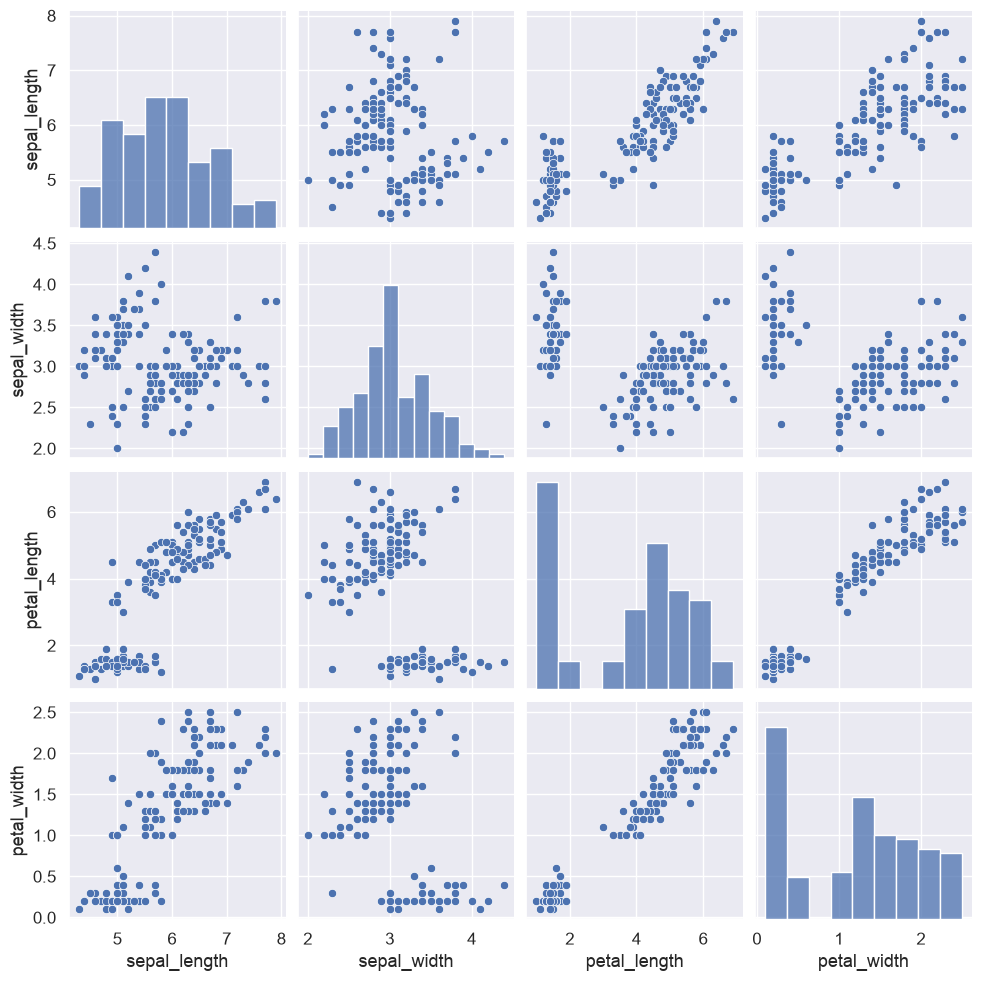

In [68]:
sns.pairplot(data=iris);

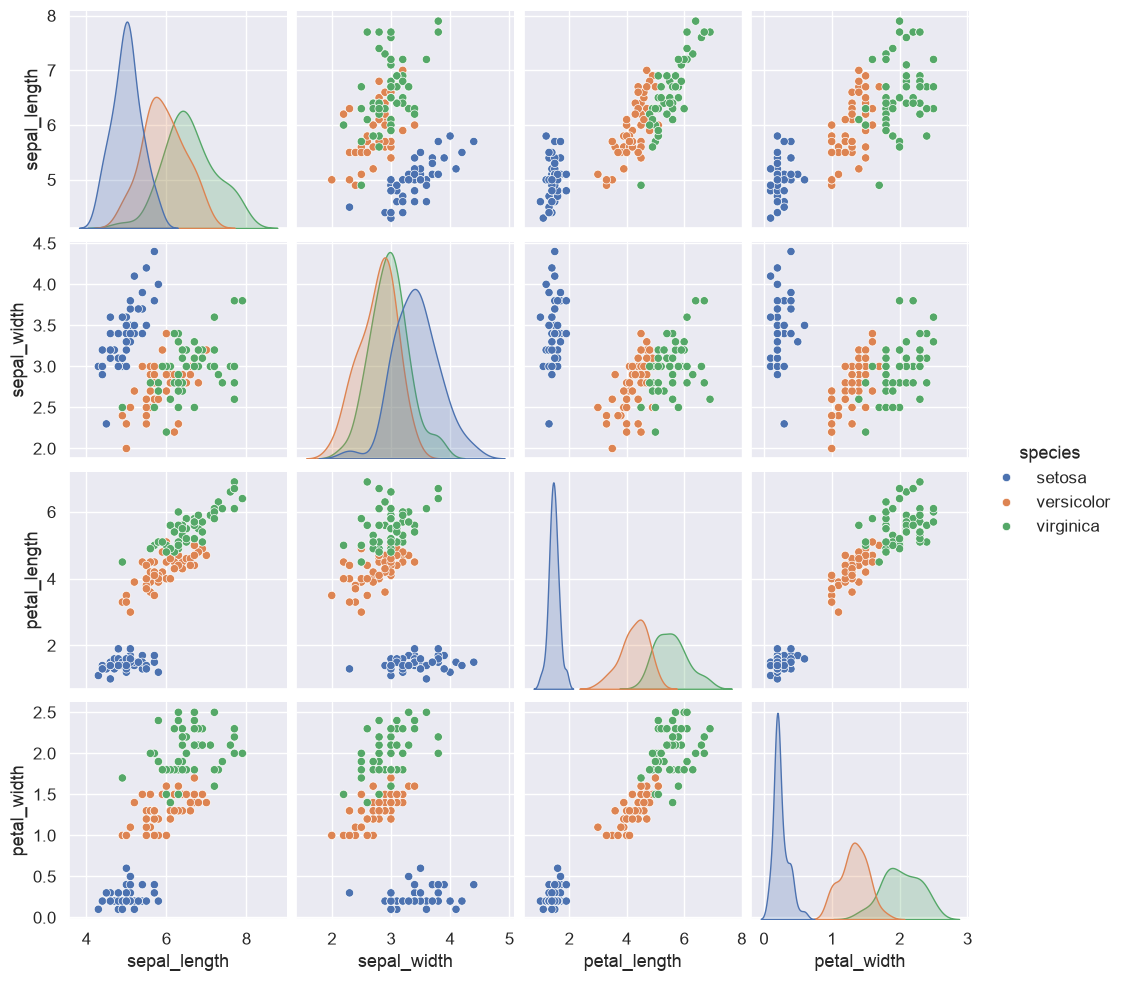

In [69]:
sns.pairplot(data=iris, hue='species');

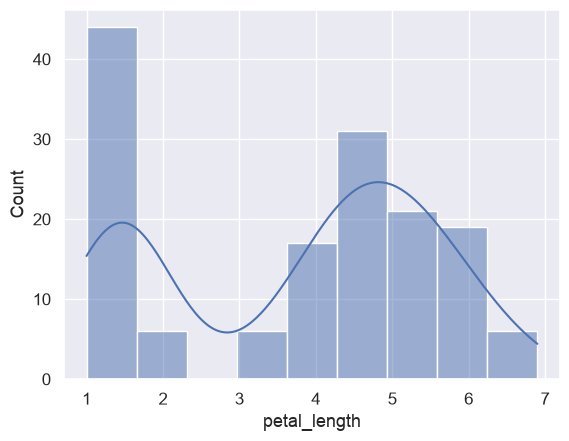

In [70]:
sns.histplot(x="petal_length", data=iris, kde=True);

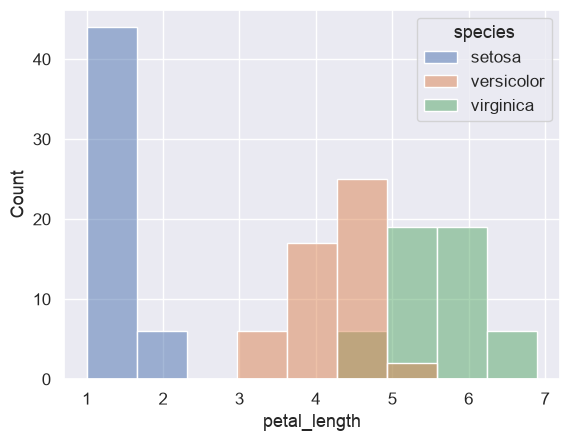

In [71]:
sns.histplot(data=iris, x="petal_length", hue="species");

### Zapis wykresu Seaborn

Wykresy `relplot`, `catplot` i `pairplot` zwracają obiekt, który ma metodę `savefig()`.

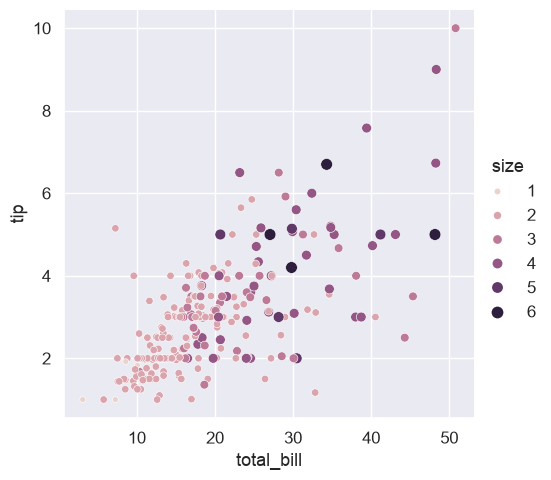

In [72]:
g = sns.relplot(data=tips, x='total_bill', y='tip', size='size', hue='size')
g.savefig('tips.png', dpi=300, bbox_inches='tight')

## 6. Plotly – wykresy interaktywne

Plotly tworzy **interaktywne** wykresy: po najechaniu myszą widać wartości, można przybliżać, przesuwać i ukrywać serie danych. Wykresy można zapisać do samodzielnego pliku HTML.

Plotly ma dwa interfejsy:
- **`plotly.graph_objects`** – niskopoziomowy, pełna kontrola, więcej kodu,
- **`plotly.express`** – wysokopoziomowy, jedna funkcja na wykres (podobnie jak w Seaborn). W praktyce używa się głównie tego.

- Strona biblioteki: [plotly.com/python](https://plotly.com/python/)
- Dokumentacja: [plotly.com/python-api-reference](https://plotly.com/python-api-reference/)

> Do wyświetlania wykresów Plotly w notatniku potrzebny jest pakiet `nbformat` (jest w `requirements.txt`).

### `graph_objects`: wykres liniowy

In [73]:
import plotly.graph_objects as go

x = [1, 2, 3, 4, 5]
y = [10, 15, 13, 17, 10]

fig = go.Figure()
fig.add_trace(go.Scatter(x=x, y=y, mode='lines+markers', name='Wykres liniowy'))
fig.update_layout(title='Wykres liniowy', xaxis_title='X', yaxis_title='Y')
fig.show()

### `graph_objects`: wykres słupkowy

In [74]:
categories = ['A', 'B', 'C', 'D']
values = [10, 15, 7, 12]

fig = go.Figure()
fig.add_trace(go.Bar(x=categories, y=values, name='Wykres słupkowy'))
fig.update_layout(title='Wykres słupkowy', xaxis_title='Kategoria', yaxis_title='Wartość')
fig.show()

### Plotly Express

Plotly Express ma wbudowane przykładowe zbiory (`px.data`), więc nie wymaga pobierania danych.

In [75]:
import plotly.express as px

gapminder = px.data.gapminder()
gapminder.head()

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4


In [76]:
fig = px.line(gapminder.query("country == 'Canada'"), x='year', y='gdpPercap', title='PKB na mieszkańca w Kanadzie')
fig.show()

In [77]:
tips = px.data.tips()

fig = px.bar(tips, x='day', y='total_bill', color='sex', barmode='group', title='Suma rachunków w poszczególne dni, według płci')
fig.show()

### Zbiór Iris

Kolejne parametry (`color`, `marginal_x`, `trendline`...) dodają do wykresu rozrzutu nowe elementy.

In [78]:
iris = px.data.iris()
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species,species_id
0,5.1,3.5,1.4,0.2,setosa,1
1,4.9,3.0,1.4,0.2,setosa,1
2,4.7,3.2,1.3,0.2,setosa,1
3,4.6,3.1,1.5,0.2,setosa,1
4,5.0,3.6,1.4,0.2,setosa,1


In [79]:
px.scatter(data_frame=iris, x='sepal_length', y='sepal_width')

In [80]:
px.scatter(data_frame=iris, x='sepal_length', y='sepal_width', width=500, height=400)

In [81]:
px.scatter(data_frame=iris, x='sepal_length', y='sepal_width', width=700, height=400, color='species')

In [82]:
px.scatter(data_frame=iris, x='sepal_length', y='sepal_width', width=700,
           height=400, color='species', marginal_x='box')

In [83]:
px.scatter(data_frame=iris, x='sepal_length', y='sepal_width', width=700,
           height=400, color='species', marginal_x='violin', marginal_y='box')

In [84]:
px.scatter(data_frame=iris, x='sepal_length', y='sepal_width', width=700,
           height=400, color='species', title='Iris')

In [85]:
# trendline='ols' - linia regresji liniowej (wymaga pakietu statsmodels)
px.scatter(data_frame=iris, x='sepal_length', y='sepal_width', width=700,
           height=400, color='species', title='Iris', trendline='ols')

### Zbiór tips: panele (`facet`)

In [86]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [87]:
px.scatter(data_frame=tips, x='total_bill', y='tip', facet_col='day',
           category_orders={'day': ['Thur', 'Fri', 'Sat', 'Sun']},
           trendline='ols', color='smoker')

In [88]:
px.scatter(data_frame=tips, x='total_bill', y='tip', facet_row='time',
           trendline='ols', color='smoker')

### Zbiór Gapminder: animacje

Dane o krajach świata w latach 1952–2007: oczekiwana długość życia, PKB na mieszkańca i liczba ludności.

In [89]:
px.scatter(gapminder.query('year == 2007'), x='gdpPercap', y='lifeExp',
           size='pop', color='continent', log_x=True, hover_name='country', size_max=60)

Dodając `animation_frame='year'` dostajemy animację w czasie (przycisk *Play* pod wykresem). Ten typ wykresu spopularyzował statystyk **Hans Rosling**: [jego słynny film](https://www.youtube.com/watch?v=jbkSRLYSojo).

In [90]:
px.scatter(gapminder, x='gdpPercap', y='lifeExp', size='pop', color='continent', log_x=True,
           hover_name='country', size_max=60, animation_frame='year', range_y=[25, 90])

In [91]:
px.scatter(gapminder, x='gdpPercap', y='lifeExp', size='pop', color='continent', log_x=True,
           hover_name='country', size_max=60, animation_frame='year', range_y=[25, 90],
           facet_col='continent', animation_group='country')

In [92]:
px.line(data_frame=gapminder.query("country == 'Poland'"), x='year', y='pop')

### Mapy

Plik `cities.csv` zawiera 1000 miast USA ze współrzędnymi geograficznymi. Mapa pobiera kafelki z internetu, więc wymaga połączenia.

In [93]:
miasta = pd.read_csv('cities.csv')
miasta.head()

,City,State,Population,lat,lon
0,Marysville,Washington,63269,48.051764,-122.177082
1,Perris,California,72326,33.782519,-117.228648
2,Cleveland,Ohio,390113,41.499320,-81.694361
3,Worcester,Massachusetts,182544,42.262593,-71.802293
4,Columbia,South Carolina,133358,34.000710,-81.034814


In [94]:
fig = px.scatter_map(miasta, lat='lat', lon='lon',
                     hover_name='City', hover_data=['State', 'Population'], zoom=3)

fig.update_layout(map_style='carto-positron',
                  margin={'r': 10, 't': 10, 'l': 10, 'b': 10})
fig.show()

Więcej inspiracji: [galeria wykresów Plotly](https://plotly.com/python/).

## Podsumowanie

| Biblioteka | Do czego | Cechy |
|---|---|---|
| **Pandas** `.plot()` | szybki podgląd danych | jedna linijka, na bazie Matplotlib |
| **Matplotlib** | pełna kontrola nad wykresem, publikacje, raporty | wykresy statyczne, najwięcej kodu |
| **Seaborn** | wykresy statystyczne (rozkłady, zależności, kategorie) | ładne domyślne style, praca na tabelach Pandas |
| **Plotly** | prezentacje, dashboardy, eksploracja | wykresy interaktywne, animacje, mapy |
